# SunSim vs SORCE/TIM, TSIS-1 and HARPS-N (10 years), and injection of planets

In [77]:
import os

import numpy as np
import matplotlib.pyplot as plt

from sunsim import local_path, observations as obs
from sunsim.residuals import ResidualAnalysis

plt.rcParams.update({
    "figure.figsize": (15, 9),
    "font.size": 15,
    "axes.labelsize": 15,
    "axes.titlesize": 15,
    "xtick.labelsize": 15,
    "ytick.labelsize": 15,
    "legend.fontsize": 13,
    "axes.linewidth": 0.5,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
    "lines.linewidth": 1.5,
    "lines.markersize": 3,
})

## Parameters

In [78]:
SIM_RV = os.path.join(local_path('personal_data'), 'rv-7.txt')
SIM_LC = os.path.join(local_path('personal_data'), 'lc-7.txt')

ORIGIN = '2015-07-18'                # t = 0 of the simulation
FIRST, LAST = '2015-07-18', '2024-01-28'
# FIRST, LAST = '2015-09-01', '2015-11-30'
# FIRST, LAST = '2021-05-01', '2021-07-31'

FIGURES = None # "/Users/sophiestucki/Documents/rv_opt/figures/final/"                       # folder where the figures are saved (None: not saved)

INJECT = False                        # False: only the comparison; True: also periodograms, wavelets and injection of planets
PERIODS = np.linspace(5, 500, 10)    # injected periods [days]
AMPLITUDES = np.linspace(0.1, 0.5, 21)   # injected semi-amplitudes [m/s]
N_PHASES = 100                       # times of transit per period and semi-amplitude
FAP = 1e-3                           # detection threshold
PERIOD_TOL = 0.1                     # recovered period within 10 % of the injected one
ROTATION = 26                        # [days] detections at the rotation period instead of the planet


def save(fig, name):
    if FIGURES:
        fig.savefig(os.path.join(FIGURES, name + '.pdf'), bbox_inches='tight')

## Data

In [79]:
t_s, rv_s = np.loadtxt(SIM_RV).T
_, lc_s = np.loadtxt(SIM_LC).T
window = (t_s >= obs.jd_of_date(FIRST) - obs.jd_of_date(ORIGIN)) & (t_s < obs.jd_of_date(LAST) - obs.jd_of_date(ORIGIN) + 1)
t_s, rv_s, lc_s = t_s[window], rv_s[window], lc_s[window]

harps = obs.load_harpsn(local_path('harpsn_sun'), ORIGIN, end=LAST, t_start=FIRST)
sorce = obs.load_sorce(local_path('sorce_tsi'), ORIGIN, end=LAST, t_start=FIRST)
tsis = obs.load_tsis(local_path('tsis_tsi'), ORIGIN, end=LAST, t_start=FIRST)
cuts = obs.load_interventions(local_path('harpsn_interventions'), ORIGIN)

## Comparison

In [80]:
phot = [obs.compare_photometry(sorce, t_s, lc_s), obs.compare_photometry(tsis, t_s, lc_s)]
phot = [ph for ph in phot if ph['n'] > 0]
rv = obs.compare_rv(harps, t_s, rv_s, interventions=cuts)

obs.print_summary(phot, rv)
for ph, (off_obs, off_sim) in zip(phot, obs.photometry_offsets(phot)):
    print('%-10s offset obs %.1f ppm, sim %.1f ppm' % (ph['name'], off_obs, off_sim))

SORCE/TIM  1639 days  residuals: MAD    45.6 ppm  RMS   110.8 ppm   (observed: MAD    71.1  RMS   196.2 ppm)
TSIS-1     1873 days  residuals: MAD    83.0 ppm  RMS   236.7 ppm   (observed: MAD   114.5  RMS   343.0 ppm)
  period  0:    11.5 ->    87.0  sim   75  obs   53  matched   52  shift    0  RMS 0.897 m/s
  period  1:    87.0 ->   257.0  sim  168  obs  103  matched  101  shift    0  RMS 0.874 m/s
  period  2:   257.0 ->   466.0  sim  206  obs  172  matched  170  shift    1  RMS 0.707 m/s
  period  3:   466.0 ->   633.0  sim  166  obs   86  matched   85  shift    1  RMS 0.679 m/s
  period  4:   633.0 ->   850.0  sim  215  obs  161  matched  159  shift    1  RMS 0.724 m/s
  period  5:   850.0 ->  1010.0  sim  159  obs   46  matched   45  shift   -1  RMS 0.730 m/s
  period  6:  1010.0 ->  1063.0  sim   53  obs   39  matched   38  shift    1  RMS 0.490 m/s
  period  7:  1063.0 ->  1191.0  sim  126  obs  105  matched  102  shift    1  RMS 0.690 m/s
  period  8:  1191.0 ->  1333.0  sim  

## TSI and RV

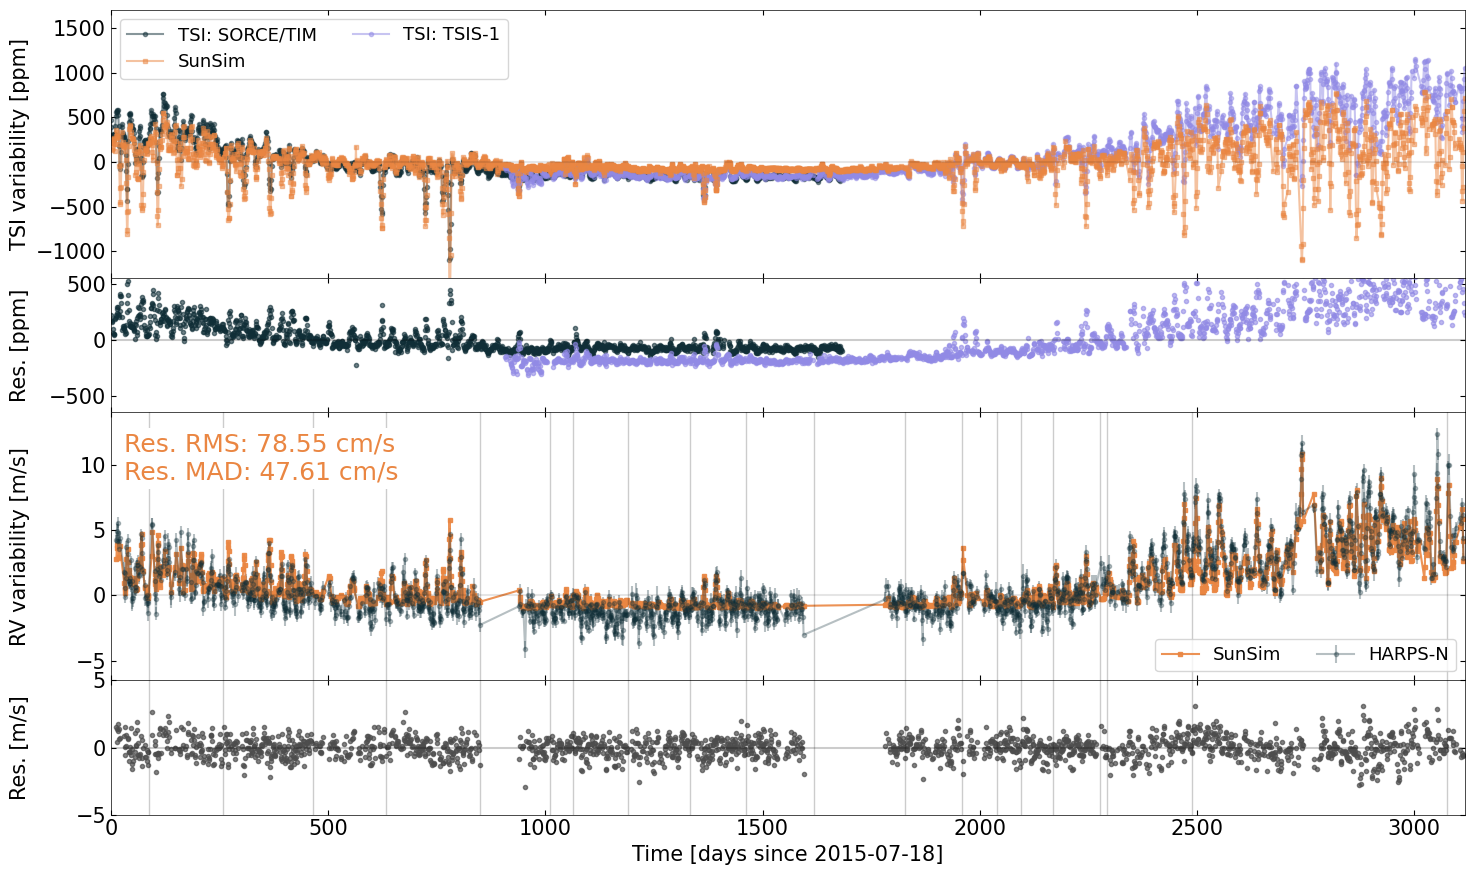

In [81]:
t0 = obs.jd_of_date(FIRST) - obs.jd_of_date(ORIGIN)
xlim = (t_s.min() - t0, t_s.max() + 1 - t0)

fig, (ax1, ax1r, ax2, ax2r) = plt.subplots(4, 1, sharex=True, gridspec_kw={'hspace': 0, 'height_ratios': [2, 1, 2, 1]})

obs.plot_photometry_comparison(phot, ax1, ax1r, t0=t0, stats=False)
ax1.set_ylim(-1300, 1700)
ax1r.set_ylim(-650, 550)

obs.plot_rv_comparison(rv, ax2, ax2r, t0=t0)
ax2.set_ylim(-6.5, 14)
ax2r.set_ylim(-5, 5)

ax2r.set_xlim(*xlim)
ax2r.set_xlabel('Time [days since %s]' % FIRST)
fig.align_ylabels([ax1, ax1r, ax2, ax2r])
fig.tight_layout()
save(fig, '10_final_res_1024_all_best_fit_{}_{}'.format(FIRST,LAST))
plt.show()

## RV

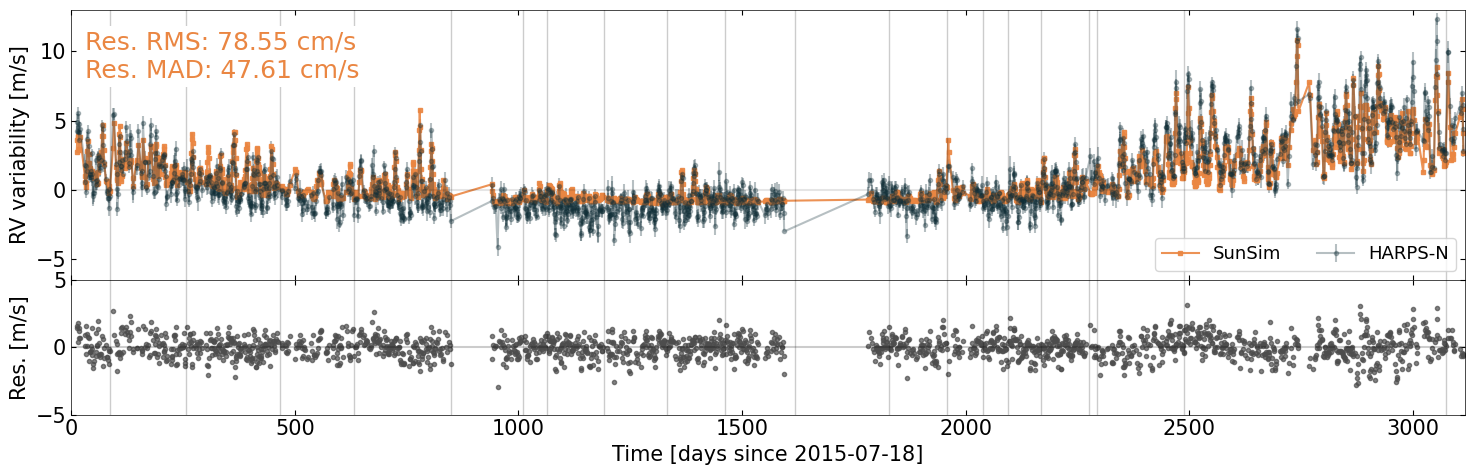

In [82]:
fig, (ax2, ax2r) = plt.subplots(2, 1, sharex=True, figsize=(15, 5), gridspec_kw={'hspace': 0, 'height_ratios': [2, 1]})
obs.plot_rv_comparison(rv, ax2, ax2r, t0=t0)
ax2.set_ylim(-6.5, 13)
ax2r.set_ylim(-5, 5)
ax2r.set_xlim(*xlim)
ax2r.set_xlabel('Time [days since %s]' % FIRST)
fig.align_ylabels([ax2, ax2r])
fig.tight_layout()
save(fig, '10_final_res_1024_non_active_rv_only_{}_{}'.format(FIRST,LAST))
plt.show()

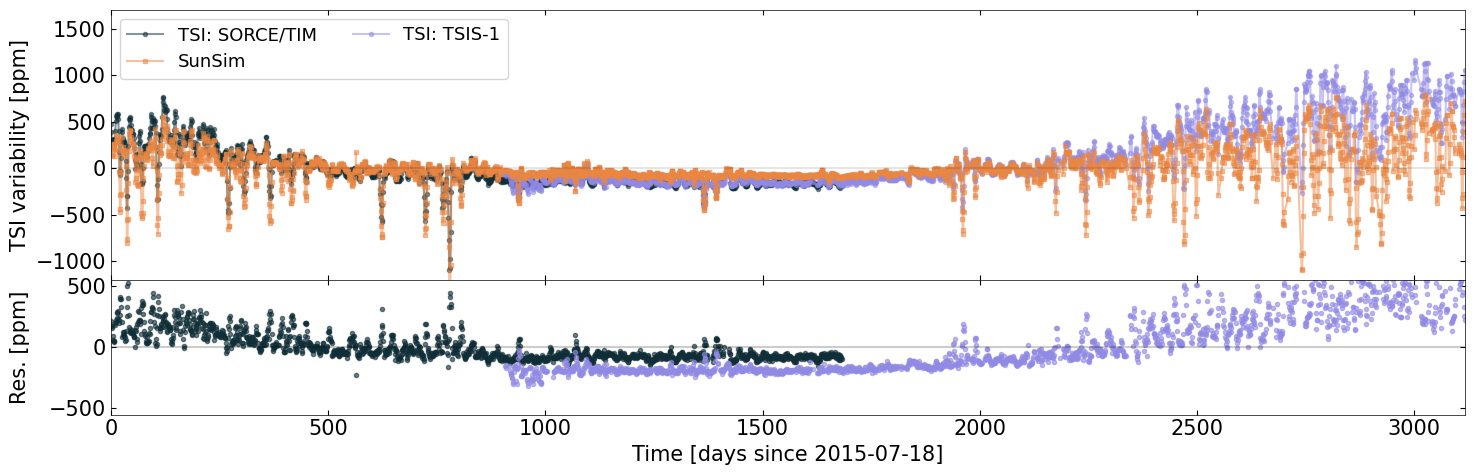

In [83]:
fig, (ax1, ax1r) = plt.subplots(2, 1, sharex=True, figsize=(15, 5), gridspec_kw={'hspace': 0, 'height_ratios': [2, 1]})
obs.plot_photometry_comparison(phot, ax1, ax1r, t0=t0, stats=False)
ax1.set_ylim(-1200, 1700)
ax1r.set_ylim(-550, 550)
ax1r.set_xlim(*xlim)
ax1r.set_xlabel('Time [days since %s]' % FIRST)
fig.align_ylabels([ax1, ax1r])
fig.tight_layout()
save(fig, '10_final_res_1024_phot_only_{}_{}'.format(FIRST,LAST))
plt.show()

## Correlation

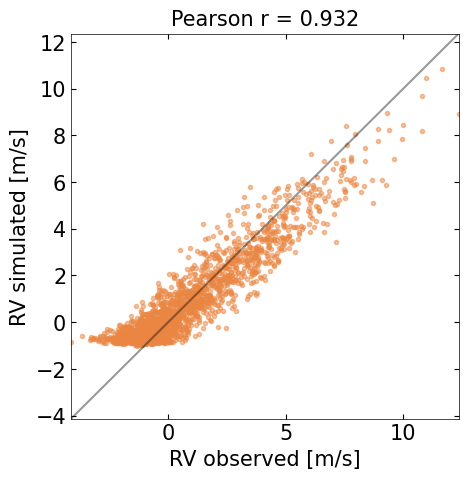

In [84]:
obs.plot_correlation(rv, label='RV')
plt.show()

## Periodograms

In [85]:
if INJECT:
    series = {'residuals': ResidualAnalysis.from_comparison(rv, 'res', name='HARPS-N - SunSim'),
              'harpsn': ResidualAnalysis.from_comparison(rv, 'obs', period_medians=True, name='HARPS-N')}

    fig, axes = plt.subplots(len(series), 1, figsize=(15, 5 * len(series)), sharex=True)
    for ax, ra in zip(axes, series.values()):
        ra.plot_periodogram(ax, mark=(ROTATION, 365))
    fig.tight_layout()
    save(fig, 'gls')
    plt.show()

## Wavelets

In [86]:
if INJECT:
    fig, axes = plt.subplots(len(series), 1, figsize=(15, 5 * len(series)), sharex=True)
    for ax, ra in zip(axes, series.values()):
        ra.plot_wavelet(ax, period_range=(2, 256))
    fig.tight_layout()
    save(fig, 'wavelet')
    plt.show()

## Injection

In [87]:
if INJECT:
    for ra in series.values():
        print(ra.name)
        ra.inject(PERIODS, AMPLITUDES, n_phases=N_PHASES, fap=FAP)

## Detection maps

In [88]:
if INJECT:
    plt.rcParams.update({"font.size": 13})
    kinds = {'FAP <= %g' % FAP: dict(),
             'and |P - P_inj| / P_inj <= %g' % PERIOD_TOL: dict(period_tol=PERIOD_TOL),
             'at the rotation (%g d) instead' % ROTATION: dict(period_tol=PERIOD_TOL, at_period=ROTATION)}

    fig, axes = plt.subplots(len(series), len(kinds), figsize=(8 * len(kinds), 6 * len(series)), squeeze=False)
    for row, ra in zip(axes, series.values()):
        for ax, (title, kw) in zip(row, kinds.items()):
            ra.plot_detection_map(ra.detection_rate(**kw), ax, title='%s: %s' % (ra.name, title))
    fig.tight_layout()
    save(fig, 'test_inj_full')
    plt.show()

In [89]:
if INJECT:
    rate_res, rate_obs = (ra.detection_rate(period_tol=PERIOD_TOL) for ra in series.values())
    ratio = np.divide(rate_res, rate_obs, out=np.full_like(rate_res, np.nan), where=rate_obs > 0)

    ax = series['residuals'].plot_detection_map(ratio, vmin=None, vmax=None, label='Detections: residuals / HARPS-N',
                                                title='|P - P_inj| / P_inj <= %g, FAP <= %g' % (PERIOD_TOL, FAP))
    save(ax.figure, 'test_inj_ratio')
    plt.show()

## Recovered semi-amplitudes and periods

In [90]:
if INJECT:
    for name, ra in series.items():
        axes = ra.plot_recovered()
        axes[0].figure.suptitle(ra.name)
        axes[0].figure.tight_layout()
        save(axes[0].figure, 'recovered_' + name)
        plt.show()